In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math

%matplotlib inline

# Setup plots to be large
plt.rcParams['figure.figsize'] = [15, 10]

def display_pair(img1, img2, title1="Image 1", title2="Image 2", cmap='gray'):
    """Helper function to visualize a pair of images side-by-side."""
    fig, ax = plt.subplots(1, 2, figsize=(20, 10))
    ax[0].imshow(img1, cmap=cmap)
    ax[0].set_title(title1)
    ax[0].axis('off')
    ax[1].imshow(img2, cmap=cmap)
    ax[1].set_title(title2)
    ax[1].axis('off')
    plt.show()

def display_single(img, title="Image", cmap='gray'):
    plt.figure(figsize=(10, 10))
    plt.imshow(img, cmap=cmap)
    plt.title(title)  # FIXED: Changed from set_title to title
    plt.axis('off')
    plt.show()

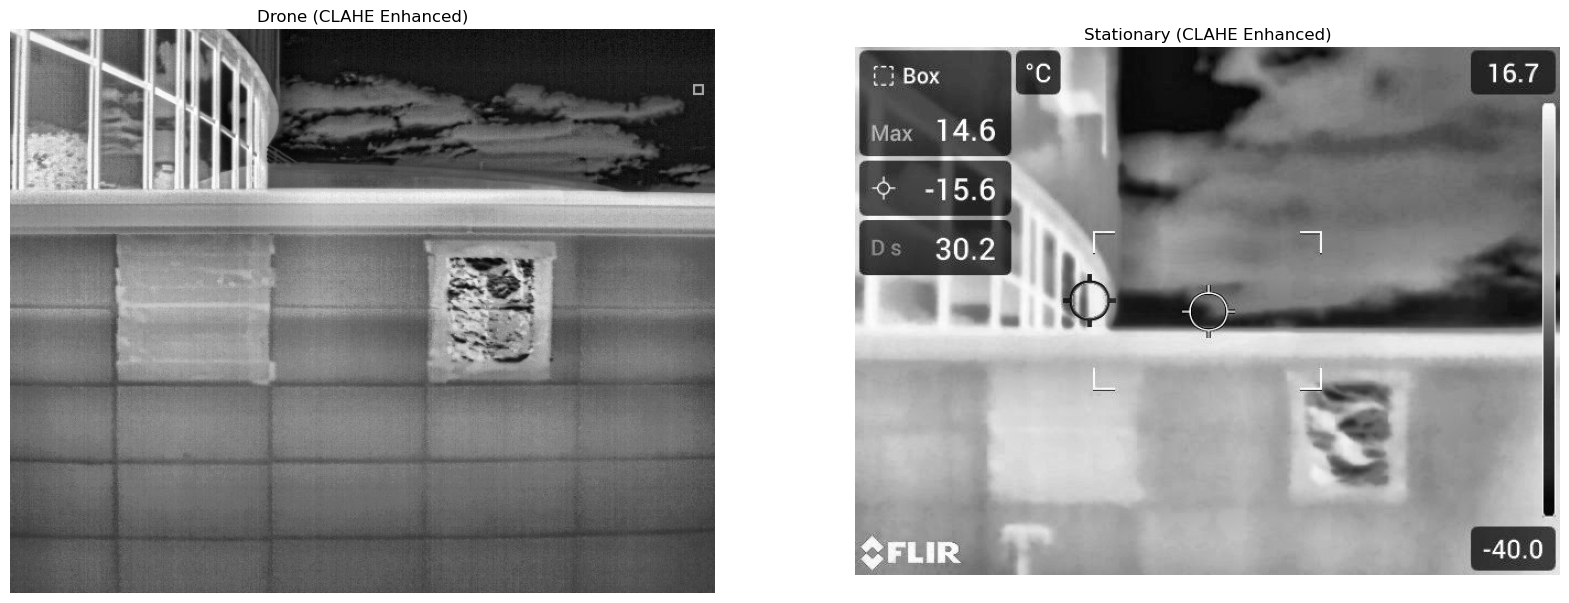

In [7]:
# --- Load Images ---
# Load as grayscale. Thermal data is inherently single-channel.
# Color palettes are just visualizations and hinder matching if different.
img_drone_bgr = cv2.imread(r"C:\Users\murat\Downloads\Drone Thermal 23 Nov.JPG")
img_stationary_bgr = cv2.imread(r"C:\Users\murat\Downloads\Stationary thermal nov 23.jpg")

# Convert to grayscale
img_drone_gray = cv2.cvtColor(img_drone_bgr, cv2.COLOR_BGR2GRAY)
img_stationary_gray = cv2.cvtColor(img_stationary_bgr, cv2.COLOR_BGR2GRAY)

# --- NEW: Apply CLAHE (Contrast Limited Adaptive Histogram Equalization) ---
# This brings out details in flat thermal regions, improving feature matching significantly.
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
img_drone_gray = clahe.apply(img_drone_gray)
img_stationary_gray = clahe.apply(img_stationary_gray)

h_stat, w_stat = img_stationary_gray.shape[:2]
h_drone, w_drone = img_drone_gray.shape[:2]

# --- Define Masks ---
# Mask for Stationary Image (image_1.png) - Masking out FLIR UI
mask_stat = np.ones_like(img_stationary_gray) * 255
mask_stat[0:int(h_stat*0.4), 0:int(w_stat*0.35)] = 0 # Top left UI
mask_stat[0:int(h_stat*0.15), int(w_stat*0.8):] = 0  # Top right temp
mask_stat[int(h_stat*0.85):, int(w_stat*0.8):] = 0   # Bottom right logo
cy, cx = h_stat // 2, w_stat // 2
cv2.circle(mask_stat, (cx, cy), 30, 0, -1)           # Center crosshair

# Mask for Drone Image (image_0.png) - Masking tiny green square
mask_drone = np.ones_like(img_drone_gray) * 255
mask_drone[0:50, w_drone-50:w_drone] = 0

display_pair(img_drone_gray, img_stationary_gray, 
             "Drone (CLAHE Enhanced)", "Stationary (CLAHE Enhanced)")

Found 405 keypoints in drone image.
Found 117 keypoints in stationary image.
Found 11 good matches after Ratio Test.

Calibration successful. Homography Matrix found:
None


AttributeError: module 'matplotlib.pyplot' has no attribute 'set_title'

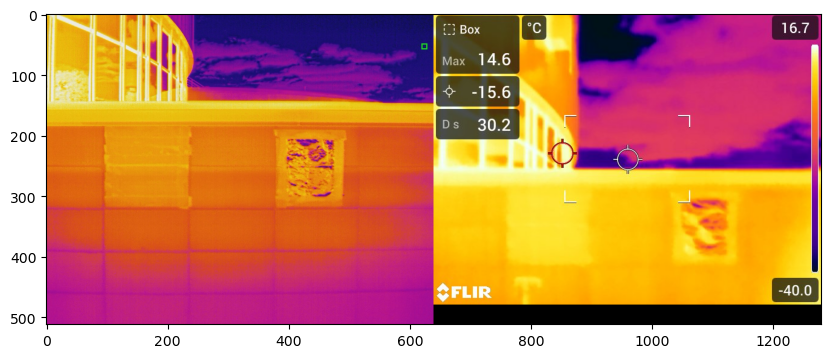

In [3]:
# --- 1. Initialization ---
# SIFT is robust for thermal images with different perspectives.
sift = cv2.SIFT_create()

# --- 2. Feature Detection & Description ---
# Detect keypoints and compute descriptors using the masks defined previously.
# The algorithm only looks for features in the white areas of the masks.
kp_drone, des_drone = sift.detectAndCompute(img_drone_gray, mask_drone)
kp_stat, des_stat = sift.detectAndCompute(img_stationary_gray, mask_stat)

print(f"Found {len(kp_drone)} keypoints in drone image.")
print(f"Found {len(kp_stat)} keypoints in stationary image.")

# --- 3. Feature Matching ---
# Use FLANN based matcher for efficiency with SIFT descriptors
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)
flann = cv2.FlannBasedMatcher(index_params, search_params)

# k=2 for k-nearest neighbors search
matches = flann.knnMatch(des_drone, des_stat, k=2)

# --- 4. Filter Matches (Lowe's Ratio Test) ---
# Keep only robust matches where the best match is significantly better than the second best.
good_matches = []
for m, n in matches:
    if m.distance < 0.7 * n.distance:
        good_matches.append(m)

print(f"Found {len(good_matches)} good matches after Ratio Test.")

# --- 5. Find Homography with RANSAC ---
MIN_MATCHES = 10
homography_matrix = None
mask_inliers = None

if len(good_matches) > MIN_MATCHES:
    # Extract coordinates of matching points
    src_pts = np.float32([kp_drone[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_stat[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    # Find Homography matrix using RANSAC to reject outliers.
    # This is the core calibration step.
    homography_matrix, mask_inliers = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    
    print("\nCalibration successful. Homography Matrix found:")
    print(homography_matrix)
    
    # Visualize inliers (matches used for the final calibration model)
    matches_mask = mask_inliers.ravel().tolist()
    draw_params = dict(matchColor=(0, 255, 0), # Green for inliers
                       singlePointColor=None,
                       matchesMask=matches_mask,
                       flags=2)
    img_matches = cv2.drawMatches(img_drone_bgr, kp_drone, 
                                  img_stationary_bgr, kp_stat, 
                                  good_matches, None, **draw_params)
    display_single(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB), 
                   "Robust Inlier Matches (RANSAC)")
else:
    print(f"Not enough matches found - {len(good_matches)}/{MIN_MATCHES}")
    # You might need to adjust mask or ratio test if this happens.

Found 1388 keypoints in drone image.
Found 226 keypoints in stationary image.
Found 61 good matches after Ratio Test.

Calibration successful. Homography Matrix found.


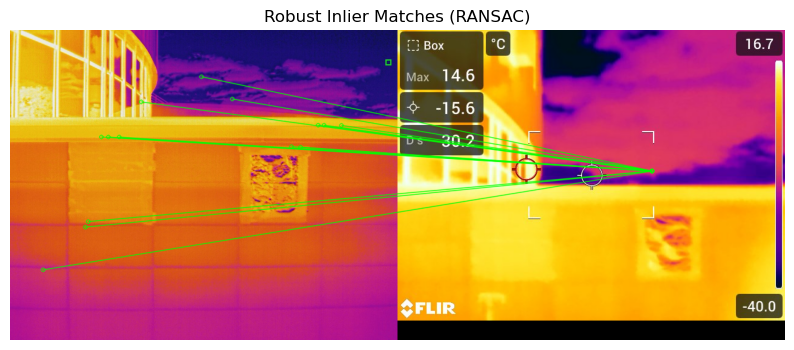

In [8]:
# --- 1. Initialization ---
# Lower contrastThreshold (0.04 -> 0.03) to detect fainter thermal features
sift = cv2.SIFT_create(contrastThreshold=0.03)

# --- 2. Feature Detection ---
kp_drone, des_drone = sift.detectAndCompute(img_drone_gray, mask_drone)
kp_stat, des_stat = sift.detectAndCompute(img_stationary_gray, mask_stat)

print(f"Found {len(kp_drone)} keypoints in drone image.")
print(f"Found {len(kp_stat)} keypoints in stationary image.")

# --- 3. Feature Matching ---
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)
flann = cv2.FlannBasedMatcher(index_params, search_params)

# Safety check for descriptors
if des_drone is not None and des_stat is not None and len(des_drone) > 2 and len(des_stat) > 2:
    matches = flann.knnMatch(des_drone, des_stat, k=2)

    # --- 4. Filter Matches (Lowe's Ratio Test) ---
    good_matches = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance: # Relaxed ratio slightly (0.7 -> 0.75)
            good_matches.append(m)

    print(f"Found {len(good_matches)} good matches after Ratio Test.")

    # --- 5. Find Homography ---
    MIN_MATCHES = 10
    homography_matrix = None
    mask_inliers = None

    if len(good_matches) > MIN_MATCHES:
        src_pts = np.float32([kp_drone[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        dst_pts = np.float32([kp_stat[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

        # RANSAC to find the matrix
        homography_matrix, mask_inliers = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
        
        if homography_matrix is not None:
            print("\nCalibration successful. Homography Matrix found.")
            
            # Visualize matches
            matches_mask = mask_inliers.ravel().tolist()
            draw_params = dict(matchColor=(0, 255, 0), 
                               singlePointColor=None,
                               matchesMask=matches_mask,
                               flags=2)
            img_matches = cv2.drawMatches(img_drone_bgr, kp_drone, 
                                          img_stationary_bgr, kp_stat, 
                                          good_matches, None, **draw_params)
            display_single(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB), 
                           "Robust Inlier Matches (RANSAC)")
        else:
            print("Error: Matches found, but Homography calculation failed (points likely collinear or bad geometry).")
    else:
        print(f"Not enough matches found - {len(good_matches)}/{MIN_MATCHES}")
else:
    print("Error: Not enough descriptors found in one of the images.")

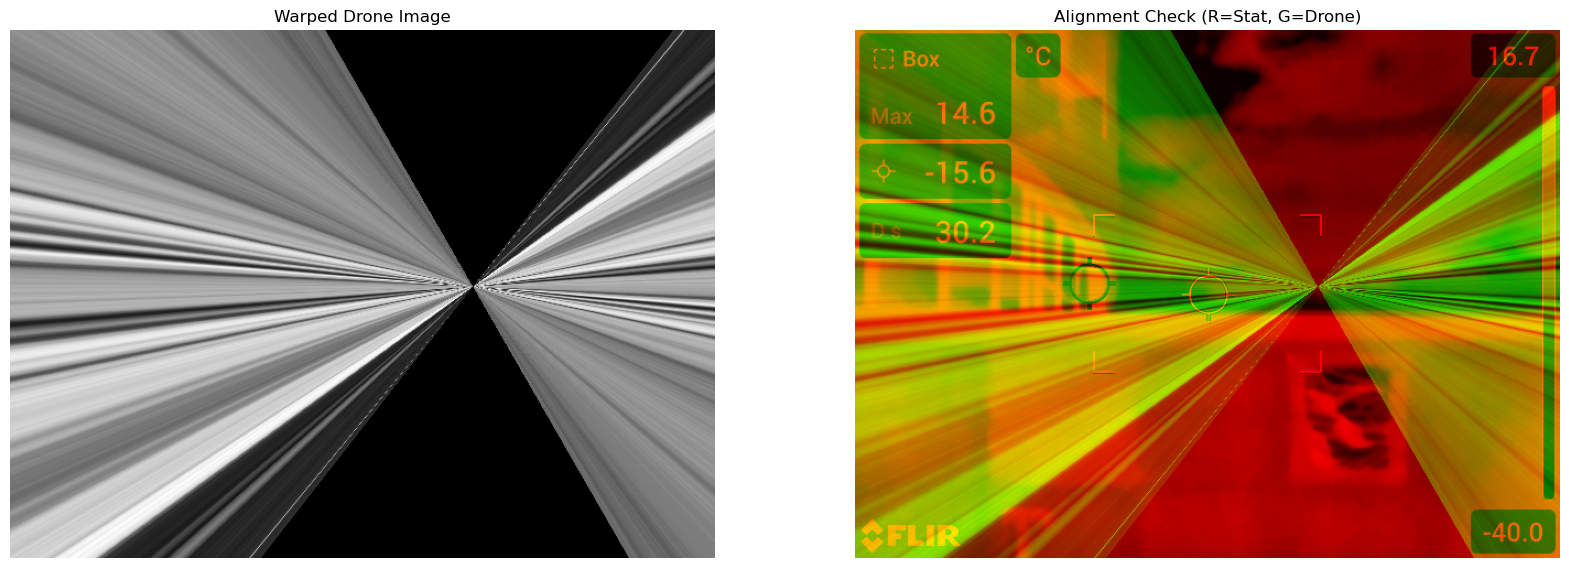

In [9]:
if homography_matrix is not None:
    h, w = img_stationary_gray.shape

    # Warp
    warped_drone_img = cv2.warpPerspective(img_drone_gray, homography_matrix, (w, h))

    # --- Visualization ---
    # Overlay: Stationary (Red) + Warped Drone (Green)
    # Yellow areas indicate perfect match.
    alignment_vis = np.zeros((h, w, 3), dtype=np.uint8)
    alignment_vis[:, :, 0] = img_stationary_gray 
    alignment_vis[:, :, 1] = warped_drone_img    
    
    display_pair(warped_drone_img, alignment_vis, 
                 "Warped Drone Image", 
                 "Alignment Check (R=Stat, G=Drone)")
else:
    print("Skipping warp - No valid calibration matrix.")

In [10]:
def calculate_rmse(img1_gray, img2_gray):
    # Mask for valid pixel areas (ignore black borders from warping)
    mask1 = img1_gray > 5 
    mask2 = img2_gray > 5
    overlap_mask = np.logical_and(mask1, mask2)
    
    if np.sum(overlap_mask) == 0:
        return None

    i1 = img1_gray[overlap_mask].astype(np.float64)
    i2 = img2_gray[overlap_mask].astype(np.float64)
    
    mse = np.mean((i1 - i2) ** 2)
    return np.sqrt(mse)

if homography_matrix is not None:
    calibration_rmse = calculate_rmse(img_stationary_gray, warped_drone_img)
    if calibration_rmse:
        print(f"RMSE in overlapping area: {calibration_rmse:.4f}")
    else:
        print("No overlap detected.")

RMSE in overlapping area: 76.9994


In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RANSACRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

%matplotlib inline
plt.rcParams['figure.figsize'] = [12, 8]

def load_and_prep(path, target_shape=None):
    # Load as grayscale (representing thermal intensity)
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    
    # Resize to target shape if provided
    if target_shape is not None:
        img = cv2.resize(img, (target_shape[1], target_shape[0]), interpolation=cv2.INTER_AREA)
    
    return img

# Paths to your uploaded crop files
stationary_path = r"C:\Users\murat\Downloads\Stationary thermal nov 23 crop.JPG"
drone_path = r"C:\Users\murat\Downloads\Drone Thermal 23 Nov crop.JPG"

In [13]:
    # 1. Load Stationary Image first (to get target dimensions)
img_stat = load_and_prep(stat_path)
h, w = img_stat.shape

# 2. Load and Resize Drone Image to match Stationary dimensions
img_drone = load_and_prep(drone_path, target_shape=(h, w))

# 3. Simulate Lower Resolution on Drone Image (Crucial Step)
# The stationary image appears much softer. We blur the drone image 
# to make the pixel comparison fair.
# We use a 15x15 kernel based on the visual blur in your samples.
img_drone_blurred = cv2.GaussianBlur(img_drone, (15, 15), 0)

# Visualize the inputs to ensure they look comparable now
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img_drone, cmap='inferno')
ax[0].set_title("Original Drone Crop")
ax[1].imshow(img_drone_blurred, cmap='inferno')
ax[1].set_title("Blurred Drone (To match target)")
ax[2].imshow(img_stat, cmap='inferno')
ax[2].set_title("Stationary Crop (Target)")
plt.show()

AttributeError: 'NoneType' object has no attribute 'shape'